Build a Regression model to forecast the exact number of product units
demanded per store each month.

1. Dataset Sales Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("Ecommerce_Sales_Prediction_Dataset.csv")

In [3]:
df.head()

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17


In [4]:
df.tail()

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
995,22-09-2025,Fashion,740.06,49.06,Regular,1890.83,34
996,23-09-2025,Electronics,517.10,28.48,Premium,8011.66,21
997,24-09-2025,Electronics,683.43,12.98,Occasional,3408.51,19
998,25-09-2025,Sports,51.26,21.85,Occasional,7335.62,26
999,26-09-2025,Home Decor,93.94,29.68,Regular,4258.11,39


In [5]:
df.shape

(1000, 7)

In [6]:
df.columns

Index(['Date', 'Product_Category', 'Price', 'Discount', 'Customer_Segment',
       'Marketing_Spend', 'Units_Sold'],
      dtype='object')

In [7]:
df.dtypes

,0
Date,object
Product_Category,object
Price,float64
Discount,float64
Customer_Segment,object
Marketing_Spend,float64
Units_Sold,int64


In [8]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1000 non-null   object 
 1   Product_Category  1000 non-null   object 
 2   Price             1000 non-null   float64
 3   Discount          1000 non-null   float64
 4   Customer_Segment  1000 non-null   object 
 5   Marketing_Spend   1000 non-null   float64
 6   Units_Sold        1000 non-null   int64  
dtypes: float64(3), int64(1), object(3)
memory usage: 54.8+ KB


In [9]:
df.isnull().sum()

,0
Date,0
Product_Category,0
Price,0
Discount,0
Customer_Segment,0
Marketing_Spend,0
Units_Sold,0


In [10]:
df.duplicated().sum()

np.int64(0)

2. Exploratory Data Analysis (EDA)

In [11]:
#Numerical and Categorical Variable
numerical_column = ['Price', 'Discount', 'Marketing_Spend', 'Units_Sold']
categorical_column = ['Date', 'Product_Category', 'Customer_Segment']

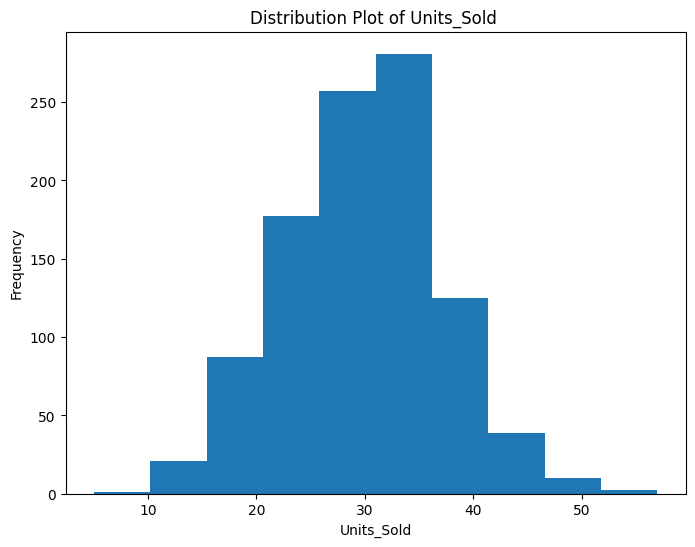

In [12]:
#distribution plot
#histogram
plt.figure(figsize = (8, 6))
plt.hist(df['Units_Sold'])
plt.xlabel('Units_Sold')
plt.ylabel('Frequency')
plt.title('Distribution Plot of Units_Sold ')
plt.show()

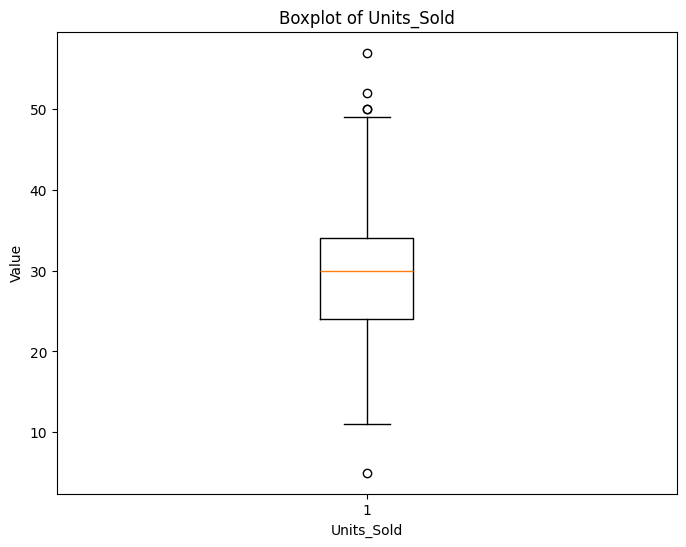

In [13]:
#boxplot
plt.figure(figsize = (8, 6))
plt.boxplot(df['Units_Sold'])
plt.xlabel('Units_Sold')
plt.ylabel('Value')
plt.title('Boxplot of Units_Sold')
plt.show()

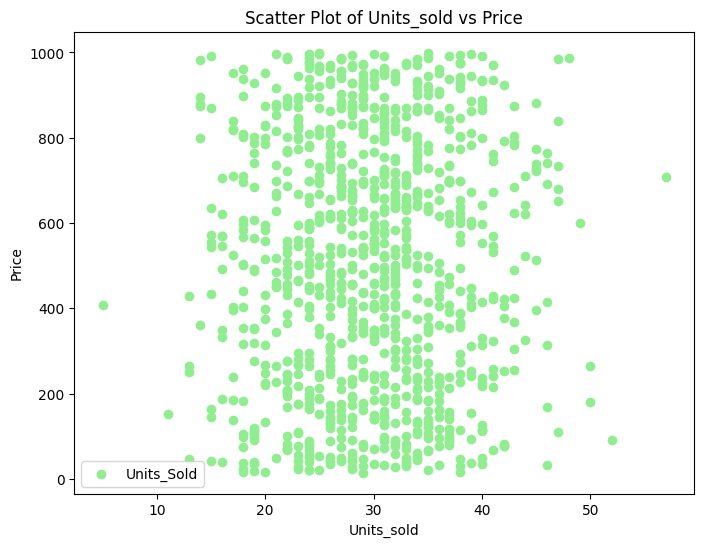

In [14]:
#scatter plot
plt.figure(figsize = (8, 6))
plt.scatter(df['Units_Sold'], df['Price'], color='lightgreen', label='Units_Sold')
plt.ylabel('Price')
plt.xlabel('Units_sold')
plt.title('Scatter Plot of Units_sold vs Price')
plt.legend()
plt.show()

3. Data Pre-processing

In [15]:
#Handle missing values, if present.
df.isnull().sum()
df = df.dropna()

In [16]:
#Check and remove duplicate records if required.
df.duplicated().sum()
df = df.drop_duplicates()

In [17]:
#Identify numerical and categorical variables.
numerical_column = ['Price', 'Discount', 'Marketing_Spend', 'Units_Sold']
categorical_column = ['Date', 'Product_Category', 'Customer_Segment']

In [18]:
#Convert categorical variables into numerical form.
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
df['Date'] = label_encoder.fit_transform(df['Date'])
df['Product_Category'] = label_encoder.fit_transform(df['Product_Category'])
df['Customer_Segment'] = label_encoder.fit_transform(df['Customer_Segment'])

4. Correlation Analysis

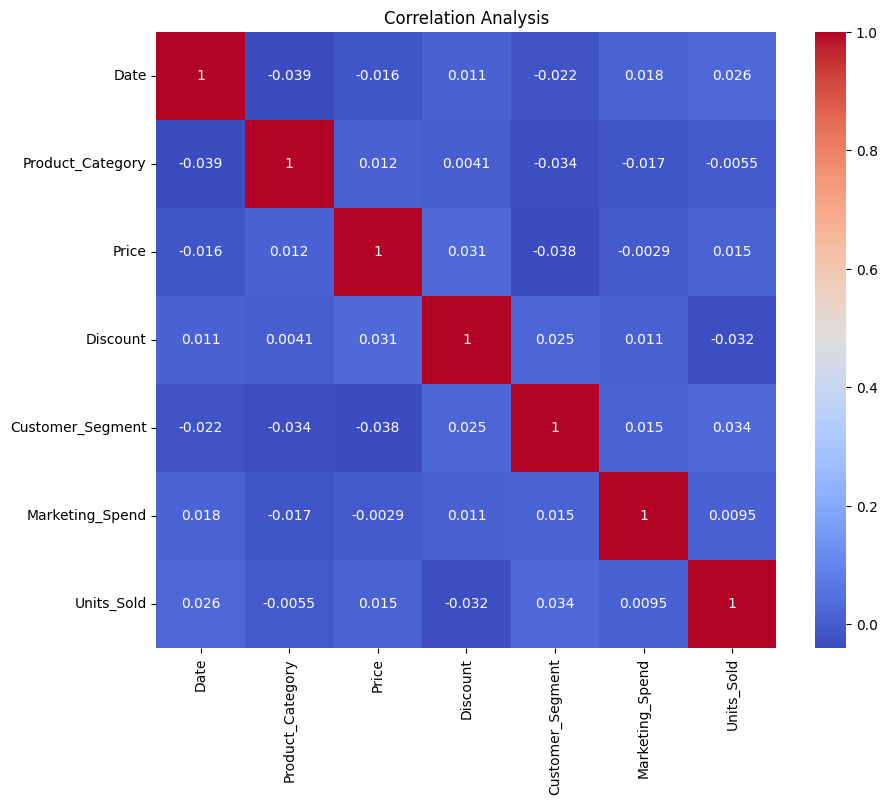

In [19]:
#correlation analysis
import seaborn as sns
#heatmap
correlation = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Analysis')
plt.show()

5. Covariance Analysis

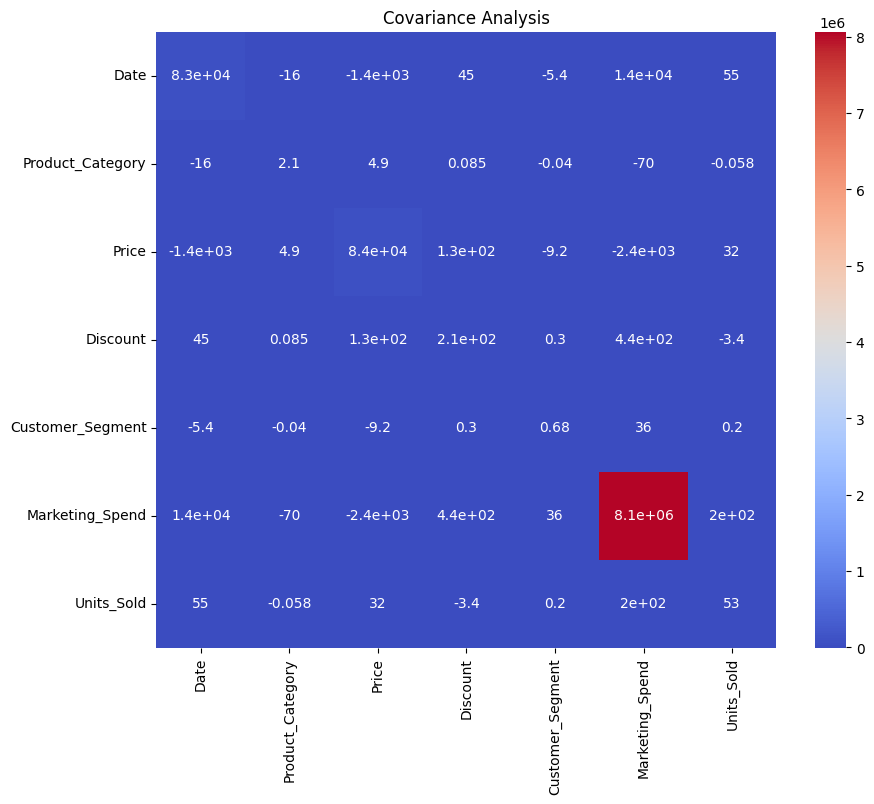

In [20]:
#covariance analysis
covariance = df.cov()
plt.figure(figsize=(10, 8))
sns.heatmap(covariance, annot=True, cmap='coolwarm')
plt.title('Covariance Analysis')
plt.show()

6. Train-Test Split

In [21]:
#train-test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df.drop('Units_Sold', axis=1), df['Units_Sold'], test_size=0.2, random_state=42)
print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

Training Samples: 800
Testing Samples: 200


In [22]:
#scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

7. Multiple Linear Regression

In [23]:
#MULTIPLE LINEAR REGRESSION
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 29.543900386811607
Coefficients: [ 1.03613881e-03 -1.26534336e-01  1.07515775e-04 -1.94564009e-02
  3.42944043e-01  1.41202866e-05]


In [24]:
from sklearn import metrics
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
print('R2 Score:', metrics.r2_score(y_test, y_pred))

Mean Absolute Error: 5.906858389972302
Mean Squared Error: 55.12606355076575
Root Mean Squared Error: 7.42469282534744
R2 Score: -0.019271741862799896


8. Ridge Regression

In [25]:
#RIDGE REGRESSION
from sklearn.linear_model import Ridge
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(x_train, y_train)
y_pred_ridge = ridge_model.predict(x_test_scaler)
print("=" * 50)
print("Alpha:",ridge_model.alpha)
print("Intercept:", ridge_model.intercept_)
print("Coefficients:", ridge_model.coef_)

Alpha: 1.0
Intercept: 29.54438898080651
Coefficients: [ 1.03611087e-03 -1.26465480e-01  1.07395733e-04 -1.94546782e-02
  3.42315103e-01  1.41240056e-05]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


9. Lasso Regression

In [26]:
#LASSO REGRESSION
from sklearn.linear_model import Lasso
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(x_train, y_train)
y_pred_lasso = lasso_model.predict(x_test_scaler)
print("=" * 50)
print("Alpha:",lasso_model.alpha)
print("Intercept:", lasso_model.intercept_)
print("Coefficients:", lasso_model.coef_)

Alpha: 1.0
Intercept: 29.51181632157802
Coefficients: [ 1.03266647e-03 -0.00000000e+00  1.02667727e-05 -1.39259633e-02
  0.00000000e+00  1.85242881e-05]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(


10. Decision Tree

In [27]:
#DECISION TREE
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor()
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)
print("Maximum Depth:", dt_model.max_depth)

Maximum Depth: None


11. Random Forest

In [28]:
#RANDOM FOREST REGRESSION
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor()
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)
print("Number of Estimators:", rf_model.n_estimators)


Number of Estimators: 100


12. Model Selection

In [29]:
prediction = {
    'Linear Regression': y_pred,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf

}

In [30]:
results = []

for model_name, y_pred in prediction.items():
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append({'Model': model_name, 'MSE': mse, 'RMSE': rmse, 'R2 Score': r2})

results_df = pd.DataFrame(results)
print(results_df)

               Model         MSE       RMSE  R2 Score
0  Linear Regression   55.126064   7.424693 -0.019272
1   Ridge Regression   54.523794   7.384023 -0.008136
2   Lasso Regression   54.308616   7.369438 -0.004157
3      Decision Tree  102.760000  10.137061 -0.900015
4      Random Forest   60.153247   7.755852 -0.112224


In [31]:
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Linear Regression': y_pred,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf
})
print(comparison_df)

     Actual  Linear Regression  Ridge Regression  Lasso Regression  \
521      47              27.57         29.738217         29.515640   
737      26              31.02         29.914359         29.534047   
740      25              30.43         30.041988         29.499637   
660      33              31.12         29.385209         29.515334   
411      31              24.63         29.205925         29.494676   
..      ...                ...               ...               ...   
408      34              28.20         29.778674         29.500025   
332      24              31.11         29.708367         29.495177   
208      18              30.72         29.485390         29.524271   
613      32              27.67         29.972958         29.512871   
78       40              32.21         29.867738         29.501160   

     Decision Tree  Random Forest  
521           22.0          27.57  
737           30.0          31.02  
740           37.0          30.43  
660           3

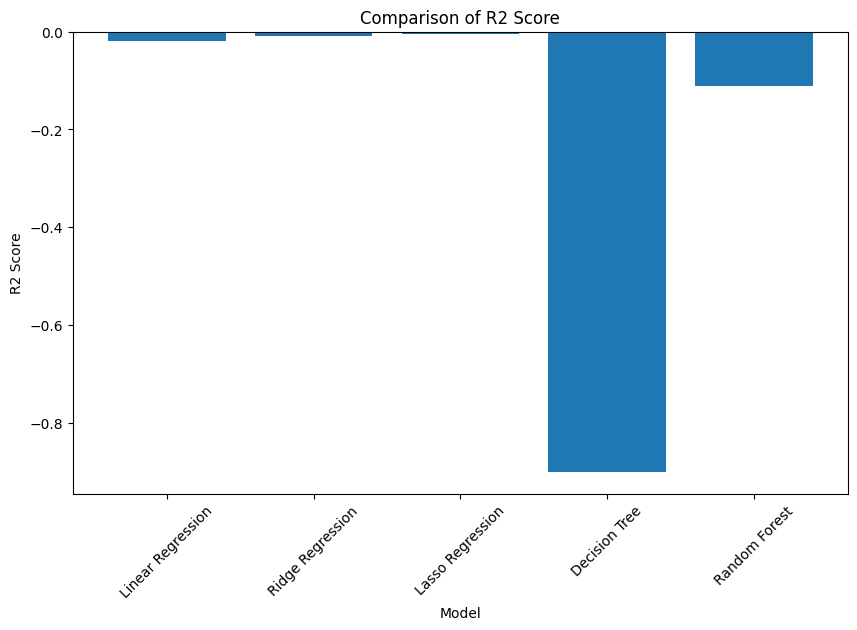

In [32]:
#bar plot
plt.figure(figsize=(10, 6))
plt.bar(results_df['Model'], results_df['R2 Score'])
plt.xlabel('Model')
plt.ylabel('R2 Score')
plt.title('Comparison of R2 Score')
plt.xticks(rotation=45)
plt.show()

In [33]:

models = {
    'Linear Regression': y_pred,
    'Ridge Regression': y_pred_ridge,
    'Lasso Regression': y_pred_lasso,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf

}

In [34]:
best_model_name = results_df.loc[results_df['R2 Score'].idxmax(), 'Model']
best_model = models[best_model_name]
print("Best Model:", best_model_name)

Best Model: Lasso Regression


13. Save the Best Model using Joblib

In [35]:
import joblib
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

In [36]:
model = joblib.load('best_model.pkl')
scaler = joblib.load('scaler.pkl')

In [37]:

from numpy.random.mtrand import sample
def predict_units_sold(price, discount, marketing_spend, date, product_category, customer_segment):
  sample_data = pd.DataFrame({
      'Price': [price],
      'Discount': [discount],
      'Marketing_Spend': [Marketing_spend],
      'Date': [date],
      'Product_Category': [product_category],
      'Customer_Segment': [customer_segment]
  })
  sample_data_scaled = scaler.transform(sample_data)
  predicted_units_sold = model.predict(sample_data_scaled)
  return predicted_units_sold[0]